# Modelo B: MobileNetV2 compacta

**Comandos:** `yes, no, up, down, left, right, on, off, stop, go`.

El Modelo B es una arquitectura **MobileNetV2**
Se entrena sobre los dos conjuntos generados en `preprocesamiento.ipynb`:

- **B/Base**: entrenamiento con `data/crudo`.
- **B/Aumentado**: entrenamiento con `data/crudo` + `data/aumentado` (SpecAugment). Validación y test **siempre** con `crudo`, para que la comparación sea justa.

In [ ]:
# --- Librerías ---
import os, json, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from torchinfo import summary
import wandb

SEED = 42
ARCHIVE_DIR = os.path.abspath("../archive")   # listas oficiales de validación/test
DATA_DIR = os.path.abspath("data")            # PNG generados en preprocesamiento.ipynb
FIG_DIR = os.path.abspath("figures")
MODEL_DIR = os.path.abspath("models")
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(MODEL_DIR, exist_ok=True)

COMMANDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
N_MELS, N_FRAMES = 64, 101

# --- Control de aleatoriedad ---
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.xpu.is_available(): torch.xpu.manual_seed_all(seed)

set_seed()
# Esto es pq estaba durando demasiado en la gráfica que tengo, según leí es mejor.
torch.use_deterministic_algorithms(False)

#xpu = backend de la arc b580
device = torch.device("xpu" if torch.xpu.is_available() else "cpu")
AMP = device.type == "xpu"
print("torch", torch.__version__, "| dispositivo:", device,
      f"({torch.xpu.get_device_name(0)})" if device.type == "xpu" else "")

WANDB_PROJECT = "proyecto1-kws"
WANDB_MODE = os.environ.get("WANDB_MODE") or ("online" if wandb.login(prompt=False) else "offline")
print("W&B:", WANDB_MODE)

/home/armando/Documentos/TEC/IA/preprocessed/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== Rusticl warning: Patched Mesa libclc not detected. Upstream libclc may contain known bugs or breaking changes and isn't guaranteed to work reliably. Please visit https://gitlab.freedesktop.org/karolherbst/mesa-libclc for more information. ===


torch 2.14.1+xpu | dispositivo: xpu (Intel(R) Arc(TM) B580 Graphics)
W&B: offline


## 1. Datos y particiones

Se usan las listas oficiales del dataset (`validation_list.txt`, `testing_list.txt`).
Todo lo que no está en esas listas es entrenamiento.

Las imágenes (uint8, 64×101) se cargan completas en memoria (~250 MB por conjunto), así el entrenamiento no lee disco en cada batch.

In [2]:
# --- Partición oficial (por hablante) ---
def read_list(name):
    with open(os.path.join(ARCHIVE_DIR, name)) as fh:
        return {l.strip().replace(".wav", ".png") for l in fh if l.split("/")[0] in COMMANDS}

val_set, test_set = read_list("validation_list.txt"), read_list("testing_list.txt")
files = [f"{c}/{f}" for c in COMMANDS for f in sorted(os.listdir(f"{DATA_DIR}/crudo/{c}"))]
split = np.array(["val" if f in val_set else "test" if f in test_set else "train" for f in files])
labels = np.array([COMMANDS.index(f.split("/")[0]) for f in files])

def load_images(ds):
    return np.stack([np.array(Image.open(f"{DATA_DIR}/{ds}/{f}")) for f in tqdm(files, desc=ds)])

X = {ds: load_images(ds) for ds in ("crudo", "aumentado")}
assert X["crudo"].shape == (len(files), N_MELS, N_FRAMES) and X["crudo"].dtype == np.uint8

counts = pd.DataFrame({s: np.bincount(labels[split == s], minlength=10) for s in ("train", "val", "test")},
                      index=COMMANDS)
counts.loc["total"] = counts.sum()
counts


crudo:   0%|          | 0/38546 [00:00<?, ?it/s]


crudo:   1%|▏         | 520/38546 [00:00<00:07, 5195.11it/s]


crudo:   3%|▎         | 1040/38546 [00:00<00:07, 5152.92it/s]


crudo:   4%|▍         | 1576/38546 [00:00<00:07, 5246.82it/s]


crudo:   5%|▌         | 2101/38546 [00:00<00:06, 5208.95it/s]

...


aumentado:  97%|█████████▋| 37272/38546 [00:07<00:00, 4778.36it/s]


aumentado:  98%|█████████▊| 37751/38546 [00:07<00:00, 4688.58it/s]


aumentado:  99%|█████████▉| 38221/38546 [00:08<00:00, 4669.67it/s]


aumentado: 100%|██████████| 38546/38546 [00:08<00:00, 4720.65it/s]

,train,val,test
yes,3228,397,419
no,3130,406,405
up,2948,350,425
down,3134,377,406
left,3037,352,412
right,3019,363,396
on,3086,363,396
off,2970,373,402
stop,3111,350,411
go,3106,372,402


In [3]:
# --- Normalización y tensores ---
tr = split == "train"
MEAN = float(X["crudo"][tr].mean() / 255)
STD = float(X["crudo"][tr].std() / 255)
print(f"mean = {MEAN:.4f} | std = {STD:.4f}")

def to_tensor(imgs):
    return ((torch.from_numpy(imgs).float() / 255 - MEAN) / STD).unsqueeze(1)

y_all = torch.from_numpy(labels).long()
DATASETS = {
    "base":      TensorDataset(to_tensor(X["crudo"][tr]), y_all[tr]),
    "aumentado": TensorDataset(torch.cat([to_tensor(X["crudo"][tr]), to_tensor(X["aumentado"][tr])]),
                               torch.cat([y_all[tr], y_all[tr]])),
}
VAL = TensorDataset(to_tensor(X["crudo"][split == "val"]), y_all[split == "val"])
TEST = TensorDataset(to_tensor(X["crudo"][split == "test"]), y_all[split == "test"])
for k, d in {**DATASETS, "val": VAL, "test": TEST}.items():
    print(f"{k:10s}: {len(d):6d} muestras")

mean = 0.3237 | std = 0.2364


base      :  30769 muestras
aumentado :  61538 muestras
val       :   3703 muestras
test      :   4074 muestras


## 2. Arquitectura: MobileNetV2

De acuerdo a la investigación, el MobileNetV2 es una arquitectura convolucional desarrollada y adaptada para procesamiento de audios en espectrogramas. El reconocimiento de keywords opera mediante streaming continuo de audio, la ligereza de esta arquitectura es ideal para no saturarr la CPU o la NPU del teléfono. No consume mucha batería y tiene una huella de memoria reducida.

**Bloque base: *inverted residual* con *linear bottleneck*.**
1. Conv 1×1 de **expansión** (factor `t`): pasa de pocos a muchos canales.
2. Conv 3×3 **depthwise** (un filtro por canal): extrae patrones espacio-temporales con un costo de `9·C` en lugar de `9·C²`.
3. Conv 1×1 de **proyección lineal** (sin activación): regresa a pocos canales. Los autores muestran que una ReLU en el espacio comprimido destruye información, por eso esta capa es lineal.
4. **Conexión residual** cuando entrada y salida tienen la misma forma: mejora el flujo de gradiente y permite apilar más bloques.

**Adaptaciones al problema (decisiones de diseño).**
- **Entrada de 1 canal 64×101** en lugar de RGB 224×224. Por eso el *stem* usa stride 1 (no reduce la resolución al inicio) y solo hay **3 reducciones** (64×101 → 32×51 → 16×26 → 8×13). Con las 5 de ImageNet quedaría un mapa de 2×4 y se perdería resolución temporal.
- **Profundidad y anchos reducidos**: 8 bloques con canales 16→24→32→64→96 (la versión original tiene 17 bloques y llega a 320 canales). Con ~38 k clips un modelo de 3.4 M parámetros sobreajustaría con facilidad; se apunta a ~0.2–0.3 M.
- **Global Average Pooling + Dropout + Linear** en lugar de capas densas grandes: casi sin parámetros en la cabeza, lo que reduce el sobreajuste y hace al modelo menos dependiente de la posición exacta de la palabra en el tiempo.
- **`width_mult`**: multiplicador de canales del artículo original, usado como hiperparámetro para medir el compromiso exactitud/costo.

In [4]:
# --- Bloques de la arquitectura ---
def make_divisible(v, divisor=8):
    # Redondea los canales a múltiplos de 8, como en la implementación original
    new_v = max(divisor, int(v + divisor / 2) // divisor * divisor)
    return new_v + divisor if new_v < 0.9 * v else new_v

class ConvBNReLU6(nn.Sequential):
    def __init__(self, c_in, c_out, k=3, stride=1, groups=1):
        super().__init__(
            nn.Conv2d(c_in, c_out, k, stride, padding=k // 2, groups=groups, bias=False),
            nn.BatchNorm2d(c_out),
            nn.ReLU6(inplace=True),
        )

class InvertedResidual(nn.Module):
    def __init__(self, c_in, c_out, stride, expand):
        super().__init__()
        hidden = c_in * expand
        self.use_res = stride == 1 and c_in == c_out
        layers = [ConvBNReLU6(c_in, hidden, k=1)] if expand != 1 else []           # 1) expansión
        layers += [
            ConvBNReLU6(hidden, hidden, k=3, stride=stride, groups=hidden),         # 2) depthwise
            nn.Conv2d(hidden, c_out, 1, bias=False), nn.BatchNorm2d(c_out),         # 3) proyección lineal
        ]
        self.conv = nn.Sequential(*layers)

    def forward(self, x):
        return x + self.conv(x) if self.use_res else self.conv(x)                   # 4) residual

# (t = expansión, c = canales, n = repeticiones, s = stride del primer bloque)
BLOCK_CFG = [(1, 16, 1, 1), (6, 24, 2, 2), (6, 32, 2, 2), (6, 64, 2, 2), (6, 96, 1, 1)]

class MobileNetV2KWS(nn.Module):
    def __init__(self, n_classes=10, width_mult=1.0, dropout=0.2, last_channels=256):
        super().__init__()
        c_in = make_divisible(16 * width_mult)
        self.stem = ConvBNReLU6(1, c_in, k=3, stride=1)
        blocks = []
        for t, c, n, s in BLOCK_CFG:
            c_out = make_divisible(c * width_mult)
            for i in range(n):
                blocks.append(InvertedResidual(c_in, c_out, s if i == 0 else 1, t))
                c_in = c_out
        self.blocks = nn.Sequential(*blocks)
        c_last = make_divisible(last_channels * max(1.0, width_mult))
        self.head = ConvBNReLU6(c_in, c_last, k=1)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(c_last, n_classes))
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.head(self.blocks(self.stem(x)))
        return self.classifier(torch.flatten(self.pool(x), 1))

summary(MobileNetV2KWS(), input_size=(1, 1, N_MELS, N_FRAMES), depth=2,
        col_names=("output_size", "num_params", "mult_adds"), verbose=0)

Layer (type:depth-idx)                        Output Shape              Param #                   Mult-Adds
MobileNetV2KWS                                [1, 10]                   --                        --
├─ConvBNReLU6: 1-1                            [1, 16, 64, 101]          --                        --
│    └─Conv2d: 2-1                            [1, 16, 64, 101]          144                       930,816
│    └─BatchNorm2d: 2-2                       [1, 16, 64, 101]          32                        32
│    └─ReLU6: 2-3                             [1, 16, 64, 101]          --                        --
├─Sequential: 1-2                             [1, 96, 8, 13]            --                        --
│    └─InvertedResidual: 2-4                  [1, 16, 64, 101]          464                       2,585,664
│    └─InvertedResidual: 2-5                  [1, 24, 32, 51]           5,136                     15,099,312
│    └─InvertedResidual: 2-6                  [1, 24, 32, 51]   

### Costo computacional

Para el caso móvil se reportan los parámetros, las operaciones (MACs) por inferencia y la latencia en CPU de **una** muestra (como en la app), para cada `width_mult` evaluado.

In [5]:
# --- Parámetros, MACs y latencia en CPU ---
def count_macs(model):
    macs = []
    def hook(m, inp, out):
        if isinstance(m, nn.Conv2d):
            macs.append(out.numel() * m.in_channels // m.groups * m.kernel_size[0] * m.kernel_size[1])
        elif isinstance(m, nn.Linear):
            macs.append(m.in_features * m.out_features)
    hs = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    with torch.no_grad(): model(torch.zeros(1, 1, N_MELS, N_FRAMES))
    for h in hs: h.remove()
    return sum(macs)

@torch.no_grad()
def cpu_latency_ms(model, reps=200):
    model = model.eval().cpu(); x = torch.randn(1, 1, N_MELS, N_FRAMES)
    for _ in range(20): model(x)
    t = time.perf_counter()
    for _ in range(reps): model(x)
    return (time.perf_counter() - t) / reps * 1000

n_params = lambda m: sum(p.numel() for p in m.parameters())
cost = pd.DataFrame([{"width_mult": w, "parámetros": n_params(m := MobileNetV2KWS(width_mult=w).eval()),
                      "MMACs": count_macs(m) / 1e6, "latencia CPU (ms)": cpu_latency_ms(m)}
                     for w in (0.5, 1.0)]).round(2)
cost

,width_mult,parámetros,MMACs,latencia CPU (ms)
0,0.5,69210,22.91,1.86
1,1.0,209066,64.73,2.24


### Diagrama de la arquitectura

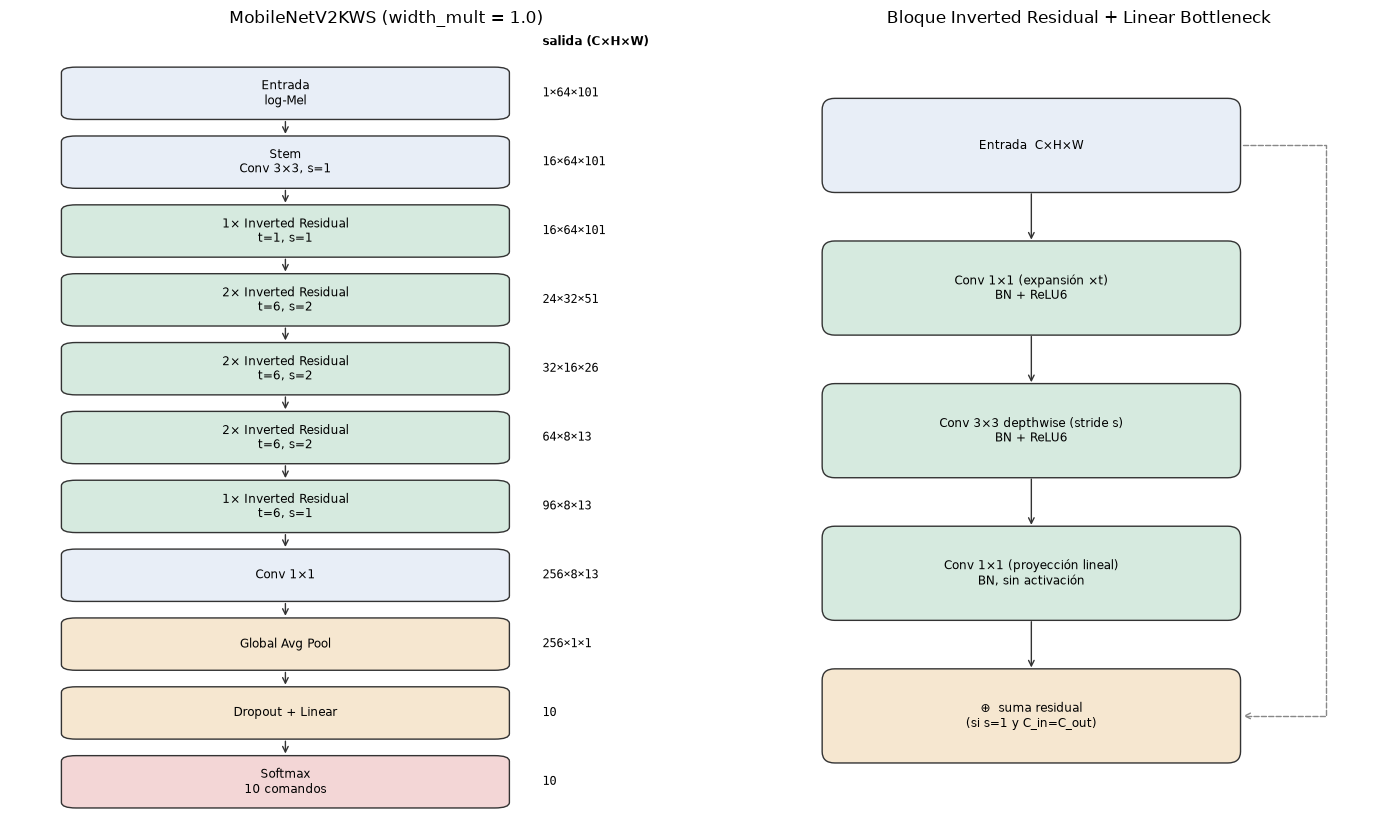

In [6]:
# --- Diagrama: flujo general (izquierda) y detalle del bloque inverted residual (derecha) ---
def stage_shapes(model):
    shapes, x = [], torch.zeros(1, 1, N_MELS, N_FRAMES)
    with torch.no_grad():
        x = model.stem(x); shapes.append(("Stem\nConv 3×3, s=1", x.shape))
        i = 0
        for t, c, n, s in BLOCK_CFG:
            for _ in range(n): x = model.blocks[i](x); i += 1
            shapes.append((f"{n}× Inverted Residual\nt={t}, s={s}", x.shape))
        x = model.head(x); shapes.append(("Conv 1×1", x.shape))
    return shapes

def draw_box(ax, x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec="#333", lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=8.5)

def arrow(ax, x0, y0, x1, y1):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="->", color="#333", lw=1))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 8.5), gridspec_kw={"width_ratios": [1.25, 1]})
rows = [("Entrada\nlog-Mel", (1, 1, N_MELS, N_FRAMES), "#e8eef7")]
rows += [(name, tuple(s), "#d6eadf" if "Inverted" in name else "#e8eef7") for name, s in stage_shapes(MobileNetV2KWS())]
rows += [("Global Avg Pool", (1, rows[-1][1][1], 1, 1), "#f6e7d0"),
         ("Dropout + Linear", (1, len(COMMANDS)), "#f6e7d0"), ("Softmax\n10 comandos", (1, len(COMMANDS)), "#f3d6d6")]
ys = np.linspace(len(rows) - 1, 0, len(rows))
for (name, shape, color), y in zip(rows, ys):
    draw_box(a1, 0, y, 2.4, 0.72, name, color)
    a1.text(1.4, y, "×".join(map(str, shape[1:])), va="center", fontsize=8.5, family="monospace")
for y0, y1 in zip(ys[:-1], ys[1:]): arrow(a1, 0, y0 - 0.37, 0, y1 + 0.37)
a1.text(1.4, ys[0] + 0.7, "salida (C×H×W)", fontsize=8.5, weight="bold")
a1.set_xlim(-1.5, 2.6); a1.set_ylim(-0.7, len(rows) - 0.1); a1.axis("off")
a1.set_title("MobileNetV2KWS (width_mult = 1.0)")

detail = [("Entrada  C×H×W", "#e8eef7"), ("Conv 1×1 (expansión ×t)\nBN + ReLU6", "#d6eadf"),
          ("Conv 3×3 depthwise (stride s)\nBN + ReLU6", "#d6eadf"),
          ("Conv 1×1 (proyección lineal)\nBN, sin activación", "#d6eadf"), ("⊕  suma residual\n(si s=1 y C_in=C_out)", "#f6e7d0")]
ys2 = np.linspace(4, 0, len(detail))
for (text, color), y in zip(detail, ys2): draw_box(a2, 0, y, 2.6, 0.62, text, color)
for y0, y1 in zip(ys2[:-1], ys2[1:]): arrow(a2, 0, y0 - 0.32, 0, y1 + 0.32)
a2.annotate("", (1.32, ys2[-1]), (1.32, ys2[0]),
            arrowprops=dict(arrowstyle="->", color="#888", ls="--", connectionstyle="bar,fraction=-0.15"))
a2.set_xlim(-1.6, 2.2); a2.set_ylim(-0.8, 4.8); a2.axis("off")
a2.set_title("Bloque Inverted Residual + Linear Bottleneck")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/modelo_b_arquitectura.png", dpi=150); plt.show()

## 3. Entrenamiento

- **Pérdida:** `CrossEntropyLoss`, con *label smoothing* como hiperparámetro (regulariza la confianza del modelo).
- **Optimizador:** `AdamW` (Adam con *weight decay* desacoplado).
- **Tasa de aprendizaje:** `OneCycleLR` (calentamiento y luego decaimiento coseno), que converge rápido y estable.
- **Early stopping:** se detiene si la pérdida de validación no mejora en `PATIENCE` épocas y se guarda el checkpoint de la mejor época.
- **Rendimiento:** precisión mixta `bfloat16` (`torch.autocast`) y formato `channels_last` durante el entrenamiento. La evaluación se hace en `float32`.
- **Métricas por época:** pérdida, accuracy y F1-macro de entrenamiento y validación, más la brecha *train − val* para vigilar el sobreajuste. Todo se envía a W&B.

In [7]:
# --- Rutinas de entrenamiento / evaluación ---
EPOCHS, PATIENCE = 30, 8

def make_loader(ds, batch_size, shuffle):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g)

def train_one_epoch(model, loader, criterion, optimizer, scheduler):
    model.train()
    tot_loss, preds, ys = torch.zeros((), device=device), [], []
    for xb, yb in loader:
        xb, yb = xb.to(device, memory_format=torch.channels_last), yb.to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=AMP):
            out = model(xb)
            loss = criterion(out, yb)
        loss.backward(); optimizer.step(); scheduler.step()
        # se acumula en la GPU para no sincronizar con la CPU en cada batch
        tot_loss += loss.detach() * len(yb)
        preds.append(out.argmax(1)); ys.append(yb)
    y, p = torch.cat(ys).cpu().numpy(), torch.cat(preds).cpu().numpy()
    tot_loss = tot_loss.item()
    return {"loss": tot_loss / len(y), "acc": accuracy_score(y, p), "f1": f1_score(y, p, average="macro")}

@torch.no_grad()
def evaluate(model, ds, criterion, batch_size=512):
    model.eval()
    tot_loss, preds, ys = 0.0, [], []
    for xb, yb in make_loader(ds, batch_size, shuffle=False):
        xb, yb = xb.to(device, memory_format=torch.channels_last), yb.to(device)
        out = model(xb)
        tot_loss += criterion(out, yb).item() * len(yb)
        preds.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(preds).numpy()
    return {"loss": tot_loss / len(y), "acc": accuracy_score(y, p), "f1": f1_score(y, p, average="macro"),
            "y": y, "pred": p}

def run_experiment(name, dataset, cfg, epochs=EPOCHS, patience=PATIENCE, train_ds=None, resume=True):
    ckpt, log_path = f"{MODEL_DIR}/modelo_b_{name}.pt", f"{MODEL_DIR}/modelo_b_{name}.json"
    # Si el entrenamiento ya terminó (p. ej. el kernel se cayó después), se carga en lugar de repetirlo
    if resume and os.path.exists(log_path) and os.path.exists(ckpt):
        with open(log_path) as fh: saved = json.load(fh)
        print(f"[{name}] ya entrenado: se carga {os.path.basename(log_path)}")
        return {**saved, "hist": pd.DataFrame(saved["hist"]), "ckpt": ckpt}
    set_seed()
    train_ds = train_ds or DATASETS[dataset]
    model = MobileNetV2KWS(width_mult=cfg["width_mult"], dropout=cfg["dropout"]).to(device, memory_format=torch.channels_last)
    loader = make_loader(train_ds, cfg["batch_size"], shuffle=True)
    criterion = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=cfg["lr"], epochs=epochs,
                                                    steps_per_epoch=len(loader))
    run = wandb.init(project=WANDB_PROJECT, group="modelo_B", job_type=dataset, name=name, mode=WANDB_MODE,
                     config={**cfg, "modelo": "B-MobileNetV2KWS", "dataset": dataset, "epochs": epochs,
                             "patience": patience, "seed": SEED, "params": n_params(model)}, reinit="finish_previous")
    hist, best, wait = [], {"val_loss": float("inf")}, 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        trm = train_one_epoch(model, loader, criterion, optimizer, scheduler)
        vam = evaluate(model, VAL, criterion)
        row = {"epoch": ep, "train_loss": trm["loss"], "train_acc": trm["acc"], "train_f1": trm["f1"],
               "val_loss": vam["loss"], "val_acc": vam["acc"], "val_f1": vam["f1"],
               "gap_acc": trm["acc"] - vam["acc"], "lr": scheduler.get_last_lr()[0], "epoch_time": time.time() - t0}
        hist.append(row); run.log(row)
        if vam["loss"] < best["val_loss"]:
            best, wait = dict(row), 0
            torch.save(model.state_dict(), ckpt)
        else:
            wait += 1
        print(f"[{name}] ep {ep:2d} | train loss {trm['loss']:.3f} acc {trm['acc']:.3f} | "
              f"val loss {vam['loss']:.3f} acc {vam['acc']:.3f} f1 {vam['f1']:.3f} | {row['epoch_time']:.1f}s")
        if wait >= patience:
            print(f"[{name}] early stopping en la época {ep}"); break
    run.summary.update({f"best_{k}": v for k, v in best.items()})
    run.finish()
    result = {"name": name, "dataset": dataset, "cfg": cfg, "best": best, "hist": hist}
    if resume:
        with open(log_path, "w") as fh: json.dump(result, fh, indent=1)
    return {**result, "hist": pd.DataFrame(hist), "ckpt": ckpt}

Prueba rápida (1 época con ~2 000 muestras, sin W&B) para verificar formas, dispositivo y tiempos antes de los entrenamientos completos.

In [8]:
# --- Smoke test ---
_mode, WANDB_MODE = WANDB_MODE, "disabled"
smoke = run_experiment("smoke", "base", {"width_mult": 1.0, "lr": 1e-3, "weight_decay": 1e-4, "dropout": 0.2,
                                         "label_smoothing": 0.0, "batch_size": 128},
                       epochs=1, resume=False, train_ds=torch.utils.data.Subset(DATASETS["base"], range(0, len(DATASETS["base"]), 15)))
WANDB_MODE = _mode
os.remove(smoke["ckpt"])

[smoke] ep  1 | train loss 2.308 acc 0.106 | val loss 2.303 acc 0.110 f1 0.020 | 7.2s


### Hiperparámetros

Tres combinaciones por conjunto:

| cfg | width_mult | lr | weight_decay | dropout | label_smoothing | batch | Idea |
|---|---|---|---|---|---|---|---|
| c1 | 1.0 | 1e-3 | 1e-4 | 0.2 | 0.00 | 128 | Configuración de referencia |
| c2 | 1.0 | 3e-3 | 5e-4 | 0.3 | 0.10 | 128 | Más regularización y lr más alto |
| c3 | 0.5 | 2e-3 | 1e-4 | 0.1 | 0.05 | 128 | Modelo más delgado (más barato en el móvil) |

In [9]:
# --- Los 6 entrenamientos: 3 configuraciones × 2 conjuntos ---
CONFIGS = {
    "c1": {"width_mult": 1.0, "lr": 1e-3, "weight_decay": 1e-4, "dropout": 0.2, "label_smoothing": 0.00, "batch_size": 128},
    "c2": {"width_mult": 1.0, "lr": 3e-3, "weight_decay": 5e-4, "dropout": 0.3, "label_smoothing": 0.10, "batch_size": 128},
    "c3": {"width_mult": 0.5, "lr": 2e-3, "weight_decay": 1e-4, "dropout": 0.1, "label_smoothing": 0.05, "batch_size": 128},
}
results = [run_experiment(f"B-{ds}-{c}", ds, cfg) for ds in ("base", "aumentado") for c, cfg in CONFIGS.items()]

wandb: Tracking run with wandb version 0.30.0


wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /home/armando/Documentos/TEC/IA/preprocessed/wandb/offline-run-20261014_150309-jgkn5n37
wandb: View this run in the terminal with `wandb leet`


[B-base-c1] ep  1 | train loss 2.282 acc 0.152 | val loss 2.175 acc 0.235 f1 0.166 | 11.9s


[B-base-c1] ep  2 | train loss 1.894 acc 0.310 | val loss 1.597 acc 0.423 f1 0.383 | 9.9s


[B-base-c1] ep  3 | train loss 1.028 acc 0.716 | val loss 0.522 acc 0.858 f1 0.856 | 10.0s


...

[B-aumentado-c3] ep 28 | train loss 0.302 acc 1.000 | val loss 0.378 acc 0.968 f1 0.968 | 11.0s


wandb: 
wandb: Run history:
wandb:      epoch ▁▁▁▂▂▂▃▃▃▃▃▄▄▄▅▅▅▅▅▆▆▆▇▇▇▇▇██
wandb: epoch_time █▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁
wandb:    gap_acc ▄▁▆▇▇▇█▇▇█▇▇█████████████████
wandb:         lr ▁▂▃▄▅▆▇█████▇▇▇▆▆▅▅▄▄▃▃▂▂▂▁▁▁
wandb:  train_acc ▁▄▇▇▇████████████████████████
wandb:   train_f1 ▁▄▇▇▇████████████████████████
wandb: train_loss █▅▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:    val_acc ▁▇▇██████████████████████████
wandb:     val_f1 ▁▇███████████████████████████
wandb:   val_loss █▃▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: 
wandb: Run summary:
wandb:      best_epoch 21
wandb: best_epoch_time 11.02469
wandb:    best_gap_acc 0.027
wandb:         best_lr 0.00078
wandb:  best_train_acc 0.99568
wandb:   best_train_f1 0.99565
wandb: best_train_loss 0.3205
wandb:    best_val_acc 0.96867
wandb:     best_val_f1 0.96893
wandb:   best_val_loss 0.37721
wandb:             +10 ...
wandb: 


wandb: You can sync this run to the cloud by running:
wandb: wandb sync /home/armando/Documentos/TEC/IA/preprocessed/wandb/offline-run-20261014_153028-zmn5g54e


wandb: Find logs at: ./wandb/offline-run-20261014_153028-zmn5g54e/logs


[B-aumentado-c3] ep 29 | train loss 0.301 acc 1.000 | val loss 0.378 acc 0.968 f1 0.968 | 11.0s
[B-aumentado-c3] early stopping en la época 29


## 4. Resultados y selección

Se elige la mejor configuración de **cada conjunto** según el **F1-macro de validación** (en la época del mejor checkpoint).
El test no se usa para escoger: solo se evalúa sobre los modelos ya seleccionados.

In [10]:
# --- Tabla de los 6 entrenamientos ---
table = pd.DataFrame([{
    "run": r["name"], "dataset": r["dataset"], **{k: r["cfg"][k] for k in ("width_mult", "lr", "weight_decay", "dropout", "label_smoothing")},
    "épocas": len(r["hist"]), "mejor época": r["best"]["epoch"],
    "train acc": r["best"]["train_acc"], "val acc": r["best"]["val_acc"], "val F1": r["best"]["val_f1"],
    "brecha acc": r["best"]["gap_acc"], "val loss": r["best"]["val_loss"],
} for r in results]).round(4)
best_runs = {ds: max((r for r in results if r["dataset"] == ds), key=lambda r: r["best"]["val_f1"])
             for ds in ("base", "aumentado")}
print("Seleccionados:", {ds: r["name"] for ds, r in best_runs.items()})
table

Seleccionados: {'base': 'B-base-c2', 'aumentado': 'B-aumentado-c2'}


,run,dataset,width_mult,lr,weight_decay,dropout,label_smoothing,épocas,mejor época,train acc,val acc,val F1,brecha acc,val loss
0,B-base-c1,base,1.0,0.001,0.0001,0.2,0.00,26,18,0.9945,0.9673,0.9675,0.0272,0.1062
1,B-base-c2,base,1.0,0.003,0.0005,0.3,0.10,29,21,0.9976,0.9714,0.9714,0.0263,0.5705
2,B-base-c3,base,0.5,0.002,0.0001,0.1,0.05,30,25,0.9992,0.9660,0.9659,0.0332,0.3874
3,B-aumentado-c1,aumentado,1.0,0.001,0.0001,0.2,0.00,19,11,0.9745,0.9633,0.9633,0.0112,0.1128
4,B-aumentado-c2,aumentado,1.0,0.003,0.0005,0.3,0.10,30,29,1.0000,0.9754,0.9754,0.0246,0.5620
5,B-aumentado-c3,aumentado,0.5,0.002,0.0001,0.1,0.05,29,21,0.9957,0.9687,0.9689,0.0270,0.3772


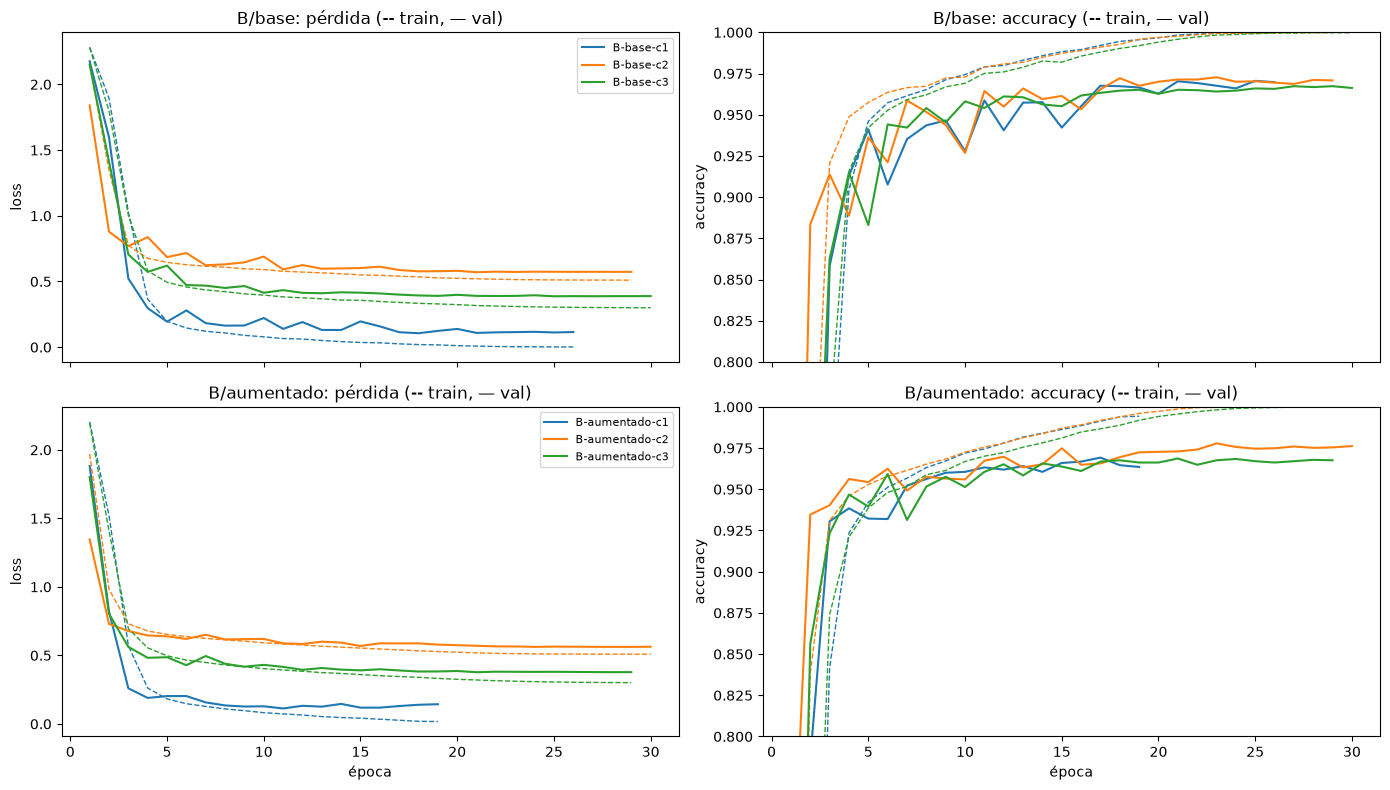

In [11]:
# --- Curvas de entrenamiento de los 6 modelos ---
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
colors = dict(zip(CONFIGS, ("tab:blue", "tab:orange", "tab:green")))
for r in results:
    h, c = r["hist"], colors[r["name"].split("-")[-1]]
    row = 0 if r["dataset"] == "base" else 1
    axes[row, 0].plot(h.epoch, h.train_loss, c=c, ls="--", lw=1); axes[row, 0].plot(h.epoch, h.val_loss, c=c, label=r["name"])
    axes[row, 1].plot(h.epoch, h.train_acc, c=c, ls="--", lw=1); axes[row, 1].plot(h.epoch, h.val_acc, c=c, label=r["name"])
for row, ds in enumerate(("base", "aumentado")):
    axes[row, 0].set_title(f"B/{ds}: pérdida (-- train, — val)"); axes[row, 0].set_ylabel("loss")
    axes[row, 1].set_title(f"B/{ds}: accuracy (-- train, — val)"); axes[row, 1].set_ylabel("accuracy")
    axes[row, 1].set_ylim(0.8, 1.0); axes[row, 0].legend(fontsize=8)
for ax in axes[1]: ax.set_xlabel("época")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/modelo_b_curvas.png", dpi=150); plt.show()

### Análisis de sobreajuste / subajuste

> *Completar con los resultados obtenidos.* Puntos a revisar en las curvas y la tabla:
> - **Sobreajuste:** la pérdida de validación sube mientras la de entrenamiento sigue bajando, o la brecha `train acc − val acc` es grande. El early stopping guarda la época previa a ese punto.
> - **Subajuste:** las dos pérdidas se quedan altas y la accuracy de entrenamiento no pasa de ~90 %.
> - En **B/Aumentado** se espera una brecha menor: SpecAugment obliga al modelo a no depender de una sola banda o de unos pocos frames. La accuracy de entrenamiento queda más baja porque la mitad de las imágenes tienen máscaras.
> - Comparar `c3` (width 0.5) contra `c1`: cuánta exactitud se pierde a cambio de ~3× menos parámetros.

## 5. Evaluación en test

In [12]:
# --- Test de los mejores modelos de cada conjunto ---
def load_model(r):
    m = MobileNetV2KWS(width_mult=r["cfg"]["width_mult"], dropout=r["cfg"]["dropout"])
    m.load_state_dict(torch.load(r["ckpt"], map_location="cpu"))
    return m.to(device, memory_format=torch.channels_last).eval()

test_res = {}
for ds, r in best_runs.items():
    m = load_model(r)
    te = evaluate(m, TEST, nn.CrossEntropyLoss())
    test_res[ds] = {"run": r["name"], "test acc": te["acc"], "test F1": te["f1"], "test loss": te["loss"],
                    "parámetros": n_params(m), "y": te["y"], "pred": te["pred"]}
    print(f"===== {r['name']} =====")
    print(classification_report(te["y"], te["pred"], target_names=COMMANDS, digits=4))
    # Se registra el resultado de test en un run de W&B propio para el modelo seleccionado
    run = wandb.init(project=WANDB_PROJECT, group="modelo_B", job_type="test", name=f"{r['name']}-test",
                     mode=WANDB_MODE, config={**r["cfg"], "dataset": ds}, reinit="finish_previous")
    run.log({"test_acc": te["acc"], "test_f1": te["f1"], "test_loss": te["loss"],
             "confusion_matrix": wandb.plot.confusion_matrix(y_true=te["y"].tolist(), preds=te["pred"].tolist(),
                                                             class_names=COMMANDS)})
    run.finish()

pd.DataFrame({ds: {k: v for k, v in d.items() if k not in ("y", "pred")} for ds, d in test_res.items()}).T

wandb: Tracking run with wandb version 0.30.0


wandb: W&B syncing is set to `offline` in this directory. Run `wandb online` or set WANDB_MODE=online to enable cloud syncing.
wandb: Run data is saved locally in /home/armando/Documentos/TEC/IA/preprocessed/wandb/offline-run-20261014_153549-736zeb5u
wandb: View this run in the terminal with `wandb leet`


wandb: 
wandb: Run history:
wandb:  test_acc ▁
wandb:   test_f1 ▁
wandb: test_loss ▁
wandb: 
wandb: Run summary:
wandb:  test_acc 0.97815
wandb:   test_f1 0.97813
wandb: test_loss 0.16282
wandb: 


wandb: You can sync this run to the cloud by running:
wandb: wandb sync /home/armando/Documentos/TEC/IA/preprocessed/wandb/offline-run-20261014_153549-736zeb5u


wandb: Find logs at: ./wandb/offline-run-20261014_153549-736zeb5u/logs


...

wandb: 
wandb: Run history:
wandb:  test_acc ▁
wandb:   test_f1 ▁
wandb: test_loss ▁
wandb: 
wandb: Run summary:
wandb:  test_acc 0.97496
wandb:   test_f1 0.97487
wandb: test_loss 0.16223
wandb: 


wandb: You can sync this run to the cloud by running:
wandb: wandb sync /home/armando/Documentos/TEC/IA/preprocessed/wandb/offline-run-20261014_153550-5y0stkr6


wandb: Find logs at: ./wandb/offline-run-20261014_153550-5y0stkr6/logs


===== B-aumentado-c2 =====
              precision    recall  f1-score   support

         yes     0.9881    0.9928    0.9905       419
          no     0.9638    0.9852    0.9744       405
          up     0.9671    0.9694    0.9683       425
        down     0.9700    0.9557    0.9628       406
        left     0.9783    0.9854    0.9819       412
       right     0.9898    0.9848    0.9873       396
          on     0.9694    0.9596    0.9645       396
         off     0.9602    0.9602    0.9602       402
        stop     0.9855    0.9951    0.9903       411
          go     0.9772    0.9602    0.9686       402

    accuracy                         0.9750      4074
   macro avg     0.9750    0.9749    0.9749      4074
weighted avg     0.9750    0.9750    0.9749      4074



,run,test acc,test F1,test loss,parámetros
base,B-base-c2,0.978154,0.978134,0.162817,209066
aumentado,B-aumentado-c2,0.974963,0.97487,0.162231,209066


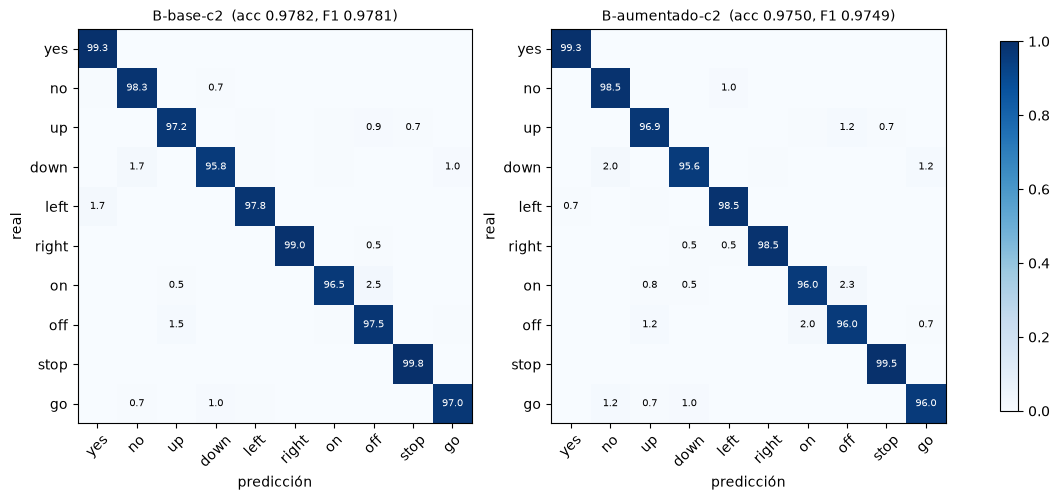

In [13]:
# --- Matrices de confusión normalizadas ---
def plot_cm(ax, cm, title):
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(10), COMMANDS, rotation=45); ax.set_yticks(range(10), COMMANDS)
    for i in range(10):
        for j in range(10):
            if cm[i, j] >= 0.005:
                ax.text(j, i, f"{cm[i, j]*100:.1f}", ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xlabel("predicción"); ax.set_ylabel("real"); ax.set_title(title, fontsize=10)
    return im

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (ds, d) in zip(axes, test_res.items()):
    cm = confusion_matrix(d["y"], d["pred"], normalize="true")
    title = f"{d['run']}  (acc {d['test acc']:.4f}, F1 {d['test F1']:.4f})"
    im = plot_cm(ax, cm, title)
    f2, a2 = plt.subplots(figsize=(6.5, 6))            # versión individual para el informe
    plot_cm(a2, cm, title); f2.tight_layout(); f2.savefig(f"{FIG_DIR}/modelo_b_cm_{ds}.png", dpi=150); plt.close(f2)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

### Modelo B final

Se elige entre B/Base y B/Aumentado por **F1-macro en test** (las clases están balanceadas, así que accuracy y F1 son parecidos, pero F1-macro penaliza más que una sola clase falle).
Este es el modelo B que se compara después con el mejor Modelo A.

In [14]:
# --- Selección del Modelo B final y guardado de resultados para la comparación con el Modelo A ---
final_ds = max(test_res, key=lambda ds: test_res[ds]["test F1"])
final_run = best_runs[final_ds]
print(f"Modelo B final: {final_run['name']} | test acc {test_res[final_ds]['test acc']:.4f} | "
      f"test F1 {test_res[final_ds]['test F1']:.4f}")

with open(f"{MODEL_DIR}/modelo_b_resultados.json", "w") as fh:
    json.dump({
        "runs": table.to_dict(orient="records"),
        "test": {ds: {k: v for k, v in d.items() if k not in ("y", "pred")} for ds, d in test_res.items()},
        "final": final_run["name"],
    }, fh, indent=2, default=float)

Modelo B final: B-base-c2 | test acc 0.9782 | test F1 0.9781


## 6. Exportación a ONNX

El modelo final se congela en modo inferencia y se exporta a ONNX. Luego se verifica con **ONNX Runtime** que produce las mismas salidas que PyTorch sobre ejemplos de test.

In [15]:
# --- Exportación ---
import onnx, onnxruntime as ort

final_model = load_model(final_run).cpu().to(memory_format=torch.contiguous_format).eval()
onnx_path = f"{MODEL_DIR}/modelo_b.onnx"
dummy = torch.randn(1, 1, N_MELS, N_FRAMES)
torch.onnx.export(final_model, (dummy,), onnx_path, input_names=["input"], output_names=["logits"],
                  dynamic_shapes={"x": {0: torch.export.Dim("batch", max=1024)}}, opset_version=18,
                  dynamo=True, external_data=False)
onnx.checker.check_model(onnx.load(onnx_path))
print(f"ONNX guardado: {onnx_path} ({os.path.getsize(onnx_path)/1024:.1f} KB)")

# --- Verificación PyTorch vs ONNX Runtime ---
sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
xs = TEST.tensors[0][:500]
with torch.no_grad(): ref = final_model(xs).numpy()
got = sess.run(["logits"], {"input": xs.numpy()})[0]
max_diff = np.abs(ref - got).max()
agree = (ref.argmax(1) == got.argmax(1)).mean()
print(f"max |Δlogits| = {max_diff:.2e} | coincidencia argmax = {agree*100:.2f}%")
assert max_diff < 1e-4 and agree == 1.0

W1014 15:35:51.856000 67057 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::nms


W1014 15:35:51.857000 67057 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align


W1014 15:35:51.857000 67057 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool


W1014 15:35:51.858000 67057 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


[torch.onnx] Obtain model graph for `MobileNetV2KWS([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `MobileNetV2KWS([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX guardado: /home/armando/Documentos/TEC/IA/preprocessed/models/modelo_b.onnx (915.0 KB)


max |Δlogits| = 3.34e-06 | coincidencia argmax = 100.00%


In [16]:
# --- Configuración del pipeline para la app ---
config = {
    "model": "modelo_b.onnx", "run": final_run["name"], "input_name": "input", "output_name": "logits",
    "input_shape": [1, 1, N_MELS, N_FRAMES], "labels": COMMANDS,
    "audio": {"sample_rate": 16000, "duration_s": 1.0, "pad_or_trim": "center"},
    "spectrogram": {"n_fft": 512, "win_length": 400, "window": "hann", "hop_length": 160, "n_mels": 64,
                    "fmin": 20.0, "fmax": 8000.0, "mel_scale": "htk", "log_offset": 1e-6, "center_pad": "reflect"},
    "image": {"minmax_per_image": True, "quantize_uint8": True, "flip_vertical": True},
    "normalization": {"scale": 1 / 255, "mean": MEAN, "std": STD},
    "output": "logits (aplicar softmax)",
}
with open(f"{MODEL_DIR}/modelo_b_config.json", "w") as fh:
    json.dump(config, fh, indent=2)
config

{'model': 'modelo_b.onnx',
 'run': 'B-base-c2',
 'input_name': 'input',
 'output_name': 'logits',
 'input_shape': [1, 1, 64, 101],
 'labels': ['yes',
  'no',
  'up',
  'down',
  'left',
  'right',
  'on',
  'off',
  'stop',
  'go'],
 'audio': {'sample_rate': 16000, 'duration_s': 1.0, 'pad_or_trim': 'center'},
 'spectrogram': {'n_fft': 512,
  'win_length': 400,
  'window': 'hann',
  'hop_length': 160,
  'n_mels': 64,
  'fmin': 20.0,
  'fmax': 8000.0,
  'mel_scale': 'htk',
  'log_offset': 1e-06,
  'center_pad': 'reflect'},
 'image': {'minmax_per_image': True,
  'quantize_uint8': True,
  'flip_vertical': True},
 'normalization': {'scale': 0.00392156862745098,
  'mean': 0.3237491951165731,
  'std': 0.2364222802840302},
 'output': 'logits (aplicar softmax)'}

Pipeline de procesado del mejor modelo b para despliegue en Android Studio

In [ ]:
import glob, json, os, random, shutil, wave
from types import SimpleNamespace
import numpy as np, onnxruntime as ort

BASE = os.getcwd()

def find_dataset():
    for base in (BASE, os.path.dirname(BASE)):
        for name in ('dataset', 'Dataset', 'data'):
            d = os.path.join(base, name)
            if os.path.isdir(os.path.join(d, 'yes')): return d

a = SimpleNamespace(
    models=os.path.join(BASE, 'models b'),   # modelo_b.onnx + modelo_b_config.json
    out=os.path.join(BASE, 'assets_b'),
    wavs=None,
    per_class=30,
)
a.wavs = a.wavs or find_dataset()
if not os.path.exists(f'{a.models}/modelo_b.onnx'):
    raise FileNotFoundError(f'No se encuentra {a.models}/modelo_b.onnx')

# Todo sale del config; solo falta calcular power y quant.
cfg = json.load(open(f'{a.models}/modelo_b_config.json'))
LABELS, IN = cfg['labels'], cfg['input_name']
SR, CLIP = cfg['audio']['sample_rate'], int(cfg['audio']['sample_rate'] * cfg['audio']['duration_s'])
S = cfg['spectrogram']; N_FFT, WINLEN, HOP, N_MELS = S['n_fft'], S['win_length'], S['hop_length'], S['n_mels']
F_MIN, F_MAX, EPS = S['fmin'], S['fmax'], S['log_offset']
N = cfg['normalization']; MEAN, STD, SCALE = N['mean'], N['std'], N['scale']
FLIP, N_FRAMES = cfg['image']['flip_vertical'], cfg['input_shape'][3]

def mel_fb_htk():   # = torchaudio melscale_fbanks(htk, norm=None)
    f = np.linspace(0, SR // 2, N_FFT // 2 + 1)
    h2m = lambda x: 2595 * np.log10(1 + x / 700); m2h = lambda m: 700 * (10 ** (m / 2595) - 1)
    fp = m2h(np.linspace(h2m(F_MIN), h2m(F_MAX), N_MELS + 2)); fd = np.diff(fp); sl = fp[None, :] - f[:, None]
    return np.maximum(0, np.minimum(-sl[:, :-2] / fd[:-1], sl[:, 2:] / fd[1:])).T.astype(np.float32)
FB = mel_fb_htk()
WIN = np.zeros(N_FFT, np.float32)   # Hann periódica de WINLEN, centrada en N_FFT
l = (N_FFT - WINLEN) // 2; WIN[l:l + WINLEN] = 0.5 - 0.5 * np.cos(2 * np.pi * np.arange(WINLEN) / WINLEN)

def pad_or_trim_center(x):
    n = len(x)
    if n < CLIP: l = (CLIP - n) // 2; return np.pad(x, (l, CLIP - n - l))
    s = (n - CLIP) // 2; return x[s:s + CLIP]

def logmel(x, power):
    x = np.pad(x.astype(np.float32), (N_FFT // 2, N_FFT // 2), mode='reflect')
    n = 1 + (len(x) - N_FFT) // HOP
    fr = x[np.arange(N_FFT)[None, :] + HOP * np.arange(n)[:, None]] * WIN
    return np.log(FB @ (np.abs(np.fft.rfft(fr, axis=1)) ** power).T + EPS).astype(np.float32)   # (64, 101)

def to_input(lm, quant):   # minmax -> uint8 -> scale -> (v-mean)/std -> flip
    x = (lm - lm.min()) / max(lm.max() - lm.min(), 1e-8)
    q = np.floor(x * 255 + 0.5) if quant == 'round' else np.floor(x * 255)
    v = (q * SCALE - MEAN) / STD
    return (v[::-1] if FLIP else v).astype(np.float32)

sess = ort.InferenceSession(f'{a.models}/modelo_b.onnx', providers=['CPUExecutionProvider'])
def run(batch): return sess.run(None, {IN: np.stack(batch)[:, None]})[0]

def read_wav(p):
    with wave.open(p) as w:
        assert w.getsampwidth() == 2 and w.getframerate() == SR, f'{p}: se espera PCM16 a {SR} Hz'
        x = np.frombuffer(w.readframes(w.getnframes()), '<i2').astype(np.float32) / 32768
        return x.reshape(-1, w.getnchannels()).mean(1) if w.getnchannels() > 1 else x

best = dict(power=2, quant='round')
if a.wavs:
    random.seed(0); clips = []
    tl = os.path.join(a.wavs, 'testing_list.txt')
    test_set = set(open(tl).read().split()) if os.path.exists(tl) else None
    for i, lab in enumerate(LABELS):
        fs = sorted(glob.glob(f'{a.wavs}/{lab}/*.wav'))
        if test_set: fs = [f for f in fs if f'{lab}/{os.path.basename(f)}' in test_set]
        random.shuffle(fs)
        clips += [(pad_or_trim_center(read_wav(f)), i) for f in fs[:a.per_class]]
    assert clips, 'No se encontraron .wav en --wavs/<comando>/'
    y = np.array([c[1] for c in clips]); res = []
    for power in (2, 1):
        lms = [logmel(c[0], power) for c in clips]
        for quant in ('round', 'floor'):
            pred = np.concatenate([run([to_input(m, quant) for m in lms[i:i + 64]]).argmax(1) for i in range(0, len(lms), 64)])
            res.append((float((pred == y).mean()), dict(power=power, quant=quant)))
    res.sort(key=lambda r: -r[0]); print(f'\nClips evaluados: {len(clips)}')
    for acc, v in res: print(f'  acc={acc:.3f}  {v}')
    best = res[0][1]
    if res[0][0] < 0.9: print('\nNinguna variante supera 0.90: revisa el preprocesamiento.')
else:
    print('\n[Sin audio de prueba: usando power=2, round SIN calibrar.')

os.makedirs(a.out, exist_ok=True)
shutil.copy(f'{a.models}/modelo_b.onnx', f'{a.out}/command_model.onnx')
FB.astype('<f4').tofile(f'{a.out}/mel_fb.bin'); WIN.astype('<f4').tofile(f'{a.out}/window.bin')
open(f'{a.out}/labels.txt', 'w').write('\n'.join(LABELS))
json.dump({'sample_rate': SR, 'clip_samples': CLIP, 'n_fft': N_FFT, 'win_length': WINLEN, 'hop': HOP, 'n_mels': N_MELS,
           'n_frames': N_FRAMES, 'log_eps': EPS, 'f_min': F_MIN, 'f_max': F_MAX, 'mel_scale': 'htk', 'power': best['power'],
           'image': {'minmax': True, 'quantize': best['quant'], 'flip_vertical': FLIP, 'scale': SCALE, 'mean': MEAN, 'std': STD},
           'mean_std_in_graph': True, 'input_name': IN, 'output_name': cfg['output_name'], 'input_shape': cfg['input_shape'],
           'classes': LABELS, 'min_confidence': 0.90, 'parity_tol': 0.05}, open(f'{a.out}/preprocessing.json', 'w'), indent=2)

t = np.arange(CLIP) / SR; rng = np.random.default_rng(0)
sigs = [0.3 * np.sin(2 * np.pi * (200 + 1500 * t) * t), 0.1 * rng.standard_normal(CLIP),
        0.2 * np.sin(2 * np.pi * 440 * t) + 0.1 * np.sin(2 * np.pi * 1200 * t), 0.25 * np.sin(2 * np.pi * (300 + 600 * np.sin(2 * np.pi * 3 * t)) * t)]
pcm = [(np.clip(s, -1, 1) * 32768).round().astype(np.int16) for s in sigs]
out = run([to_input(logmel(p.astype(np.float32) / 32768, best['power']), best['quant']) for p in pcm])
json.dump([{'label': 'synthetic', 'pcm': p.tolist(), 'logits': out[i].tolist(), 'pred': LABELS[int(out[i].argmax())]} for i, p in enumerate(pcm)],
          open(f'{a.out}/test_vectors.json', 'w'))
print('\nVariante usada:', best, '\nArchivos en', a.out, ':', sorted(os.listdir(a.out)))


Clips evaluados: 300
  acc=0.987  {'power': 2, 'quant': 'round'}
  acc=0.987  {'power': 2, 'quant': 'floor'}
  acc=0.983  {'power': 1, 'quant': 'round'}
  acc=0.983  {'power': 1, 'quant': 'floor'}

Variante usada: {'power': 2, 'quant': 'round'} 
Archivos en c:\Users\brand\Downloads\Modelos\assets_b : ['command_model.onnx', 'labels.txt', 'mel_fb.bin', 'preprocessing.json', 'test_vectors.json', 'window.bin']
